# East African coastal rainfall strip, IMERG and topo

https://disc.gsfc.nasa.gov/datasets/GPM_3IMERGDF_07/summary?keywords=IMERG%20dAILY


In [ ]:
# Day by day openDAP loop for 2 years 

import numpy as np
import xarray as xr
import pandas as pd

# ── Domain ────────────────────────────────────────────────────────────────────
LON_MIN, LON_MAX = 38.0, 52.0   # east African coastal strip
LAT_MIN, LAT_MAX = -15.0, 10.0  # 15°S – 10°N
YEARS = [2018, 2019]

# Build date list
dates = pd.date_range(f"{YEARS[0]}-01-01", f"{YEARS[-1]}-12-31", freq="D")


# ── Data: IMERG Final (V07B) via GES-DISC OPeNDAP ────────────────────────────
# 'https://gpm1.gesdisc.eosdis.nasa.gov/opendap/GPM_L3/GPM_3IMERGDF.07/
#            2019/01/3B-DAY.MS.MRG.3IMERG.20190101-S000000-E235959.V07B.nc4'

def imerg_daily_url(date):
    """OPeNDAP URL for one GPM IMERG Final Daily granule."""
    y, m, d = date.year, date.month, date.day
    doy = date.day_of_year
    fname = (f"3B-DAY.MS.MRG.3IMERG.{y}{m:02d}{d:02d}-S000000-E235959.V07B.nc4")
    # dap4: for https: 
    return (
        f"dap4://gpm1.gesdisc.eosdis.nasa.gov/opendap/GPM_L3/GPM_3IMERGDF.07/{y}/{m:02d}/"
        f"{fname}"
    )
    

# Open as a lazy xarray dataset, subsetting on the server side via OPeNDAP
# (lon runs 0–360 in IMERG; adjust slice accordingly)
ds_list = []

for date in dates:
    #if date.day == 1:
    print(date.strftime("%Y-%m-%d"))
    url = imerg_daily_url(date)
    try:
        ds_day = xr.open_dataset(
            url, engine="pydap",
            drop_variables=["time_bnds"]
        )
        # IMERG variable is 'precipitation'
        # Subset spatially (IMERG lon is –180→180 in V07)
        prec = (ds_day["precipitation"]
                .sel(lon=slice(LON_MIN, LON_MAX),
                     lat=slice(LAT_MIN, LAT_MAX))
                .squeeze("time")
                .assign_coords(time=date))
        ds_list.append(prec)
    except Exception as e:
        print(f"  skipped {date.date()}: {e}")

precip_da = xr.concat(ds_list, dim="time")   # (time, lat, lon)
precip_da.name = "precip"
precip_da.attrs.update(units="mm/day", long_name="IMERG daily precipitation")

# Show the data array characteristics
precip_da 

In [22]:
# ── 2. Grab elevation DEM at matching resolution 

# ETOPO via NOAA OPeNDAP:
ETOPO_URL = (
    "https://www.ngdc.noaa.gov/thredds/dodsC/global/ETOPO1_Ice_g_gmt4.nc"
)

dem_raw = xr.open_dataset(ETOPO_URL, engine="pydap")
elev = (dem_raw["z"]
        .sel(lon=slice(LON_MIN, LON_MAX),
             lat=slice(LAT_MIN, LAT_MAX)))
#elev = elev.rename({"x": "lon", "y": "lat"})

# Coarsen DEM to IMERG grid (nearest-neighbour resample)
elev_regrid = elev.interp(
    lat=precip_da.lat, lon=precip_da.lon, method="nearest"
)
elev_regrid.name = "elevation"
elev_regrid.attrs.update(units="m", long_name="ETOPO1 surface elevation")


# ── 3. Combine into one Dataset ───────────────────────────────────────────────
ds = xr.Dataset({"precip": precip_da, "elevation": elev_regrid})
ds.attrs.update(
    description="IMERG daily precip + ETOPO1 DEM, E African coastal strip",
    domain=f"{LAT_MIN}–{LAT_MAX}°N, {LON_MIN}–{LON_MAX}°E",
    years=str(YEARS),
)

# Save:
yearstring = "-".join(str(year) for year in YEARS)
ds.to_netcdf("/Users/bmapes/Box/VaporLakes/imerg_EastAfrica_coast_"+yearstring+".nc")

ds

/Users/bmapes/.local/share/mamba/envs/hk25/lib/python3.12/site-packages/pydap/handlers/dap.py:134: UserWarning: PyDAP was unable to determine the DAP protocol defaulting to DAP2. DAP2 is consider legacy and may result in slower responses. 
Consider replacing `http` in your `url` with either `dap2` or `dap4` to specify the DAP protocol (e.g. `dap2://<data_url>` or `dap4://<data_url>`).  For more 
information, go to https://www.opendap.org/faq-page.
  warnings.warn(


<xarray.Dataset> Size: 95MB
Dimensions:    (time: 730, lon: 130, lat: 250)
Coordinates:
  * time       (time) datetime64[ns] 6kB 2018-01-01 2018-01-02 ... 2019-12-31
  * lon        (lon) float32 520B 39.05 39.15 39.25 39.35 ... 51.75 51.85 51.95
  * lat        (lat) float64 2kB -14.95 -14.85 -14.75 -14.65 ... 9.75 9.85 9.95
Data variables:
    precip     (time, lon, lat) float32 95MB 0.0 0.0 0.0 0.0 ... 0.08 0.0 0.0
    elevation  (lat, lon) float32 130kB 486.0 586.0 ... -1.615e+03 -2.031e+03
Attributes:
    description:  IMERG daily precip + ETOPO1 DEM, E African coastal strip
    domain:       -15.0–10.0°N, 39.0–52.0°E
    years:        [2018, 2019]

In [43]:
# Plot it up: a time-lat of coast following strip 

import numpy as np
import matplotlib.pyplot as plt
import cartopy.io.shapereader as shpreader
from shapely.geometry import MultiLineString
from shapely.ops import unary_union

# ── 1. Extract coastline lon as a function of lat ─────────────────────────────
# Natural Earth 1:10m coastline (ships with cartopy)
coast_shp = shpreader.natural_earth(resolution="10m", category="physical", name="coastline")
coast_geom = unary_union([g for g in shpreader.Reader(coast_shp).geometries()])

# Sample at each IMERG lat: find the easternmost coast point in [37°E, 50°E]
# (this hugs the mainland and ignores Madagascar)
lats = ds["precip"].lat.values
coast_lon = np.full(len(lats), np.nan)
for i, lat in enumerate(lats):
    # Slice the coastline at this latitude
    pt = coast_geom.intersection(
        __import__("shapely.geometry", fromlist=["LineString"]).LineString([(37, lat), (55, lat)])
    )
    if not pt.is_empty:
        lons = np.atleast_1d([p.x for p in (pt.geoms if hasattr(pt, "geoms") else [pt])])
        coast_lon[i] = lons.min()   # easternmost = mainland, not islands


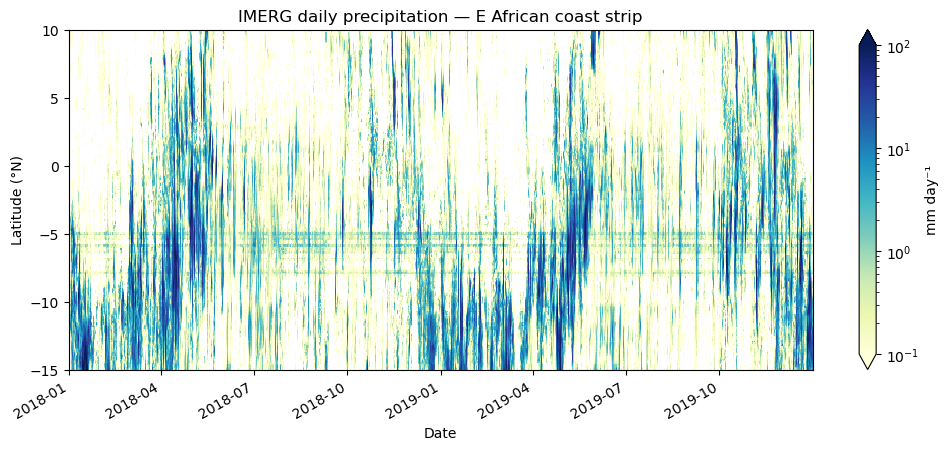

In [47]:
# Plot the coastal strip precip (log scale) 
# Average precip in a strip around the coast ─────────────────────

half = 1  # Strip half-width 

strip_mean = np.full((len(ds.time), len(lats)), np.nan)

for i, (lat, clon) in enumerate(zip(lats, coast_lon)):
    if np.isnan(clon):
        continue
    strip_mean[:, i] = (ds["precip"]
                        .sel(lat=lat,
                             lon=slice(clon - half, clon + half))
                        .mean("lon")
                        .values)
import matplotlib.colors as mcolors

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

# Replace zeros/negatives so log scale works; mask NaN stays NaN
data = np.where(strip_mean.T > 0, strip_mean.T, np.nan)

pcm = ax.pcolormesh(ds.time.values, lats, data,
                    norm=mcolors.LogNorm(vmin=0.1, vmax=100),
                    cmap="YlGnBu", shading="auto")
plt.colorbar(pcm, ax=ax, label="mm day⁻¹", extend="both")
ax.set(xlabel="Date", ylabel="Latitude (°N)",
       title="IMERG daily precipitation — E African coast strip")
fig.autofmt_xdate()

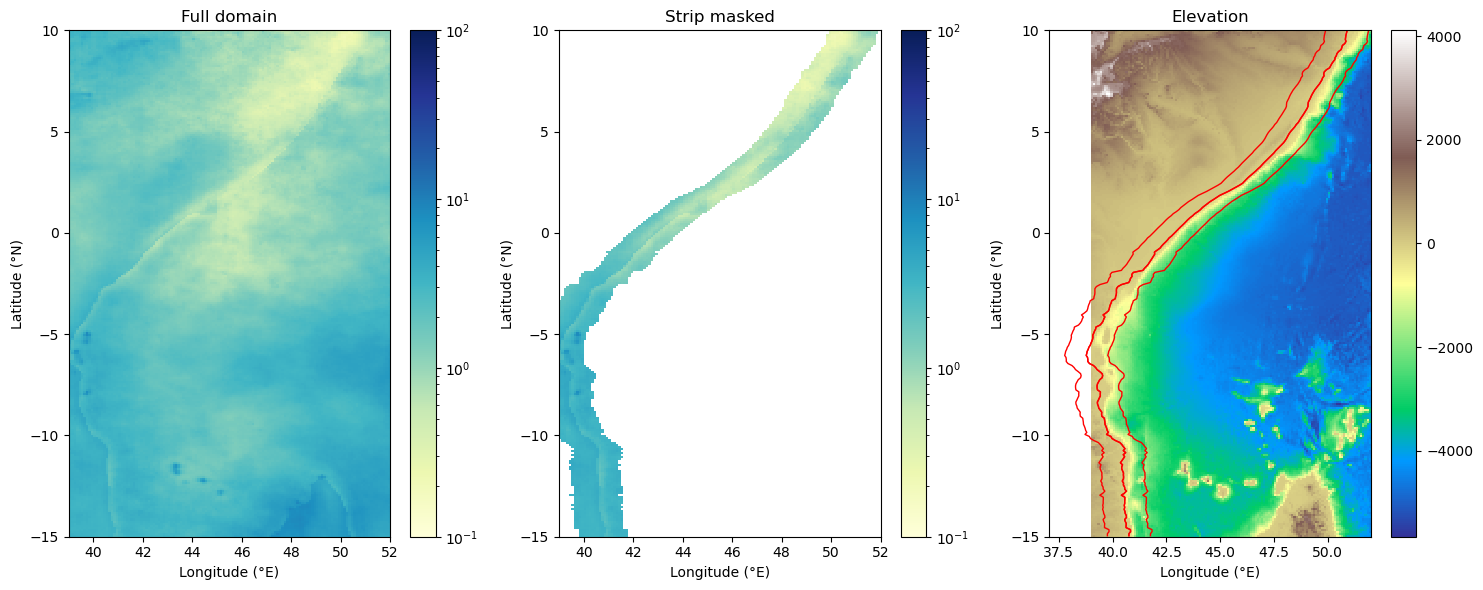

In [57]:
# Make a masked image so we can see if it worked

from shapely.geometry import LineString
import matplotlib.colors as mcolors

# One date 
date_sel = "2019-01-01"
precip_day = ds["precip"].sel(time=date_sel)   # shape (lon=130, lat=250)

# Time mean 
precip_day = ds["precip"].mean(dim="time")   # shape (lon=130, lat=250)


strip_lons = precip_day.lon.values   # 130 points
strip_lats = precip_day.lat.values   # 250 points

# Build mask with correct orientation (lon, lat)
mask = np.zeros((len(strip_lons), len(strip_lats)), dtype=bool)
for j, lat in enumerate(strip_lats):
    k = np.argmin(np.abs(lats - lat))
    clon = np.clip(coast_lon[k], LON_MIN, LON_MAX)
    if np.isnan(clon):
        continue
    mask[:, j] = (strip_lons >= clon - half) & (strip_lons <= clon + half)

precip_masked = precip_day.values.copy()   # (lon, lat)
precip_masked[~mask] = np.nan

norm = mcolors.LogNorm(vmin=0.1, vmax=100)


fig, axes = plt.subplots(1, 3, figsize=(15, 6))

datas = [precip_day.values.T, precip_masked.T, ds["elevation"].values]
titles = ["Full domain", "Strip masked", "Elevation"]
cmaps = ["YlGnBu", "YlGnBu", "terrain"]
norms = [norm, norm, None]

for ax, data, title, cmap, nm in zip(axes, datas, titles, cmaps, norms):
    pcm = ax.pcolormesh(strip_lons, strip_lats, data, cmap=cmap, norm=nm, shading="nearest")
    plt.colorbar(pcm, ax=ax)
    ax.set(title=title, xlabel="Longitude (°E)", ylabel="Latitude (°N)")

axes[2].plot(coast_lon - half, strip_lats, "r", coast_lon + half, strip_lats, "r", lw=1)
axes[2].plot(coast_lon - 0   , strip_lats, "r", coast_lon + 0   , strip_lats, "r", lw=1)

fig.tight_layout()
